# HW5 — 전처리 재현과 질문 셋
이름: 안세호 · 학번: 23013283

`data_analysis`에서 `.venv` 커널로 Restart → Run All을 실행합니다. 입력은 같은 폴더의 `sales_data.csv`이며, 출력은 `sales_clean.csv`입니다. 실습 노트북 `sales.ipynb`와 분리한 독립 실행 노트북입니다.

단계 ①~④는 전처리, 단계 ⑤~⑦은 각각 Q1~Q3입니다. 원본과 전처리 데이터의 날짜를 임의로 바꾸지 않습니다.

## 단계 ① — 읽기와 날짜 변환
원본의 1,030행·14열을 확인하고 날짜 세 칸을 변환합니다. 나이·만족도·도착일의 결측은 유지합니다. 원본 파일의 해시도 기록해 실행 후 보존 여부를 확인합니다.

In [1]:
import pandas as pd
from pathlib import Path
import hashlib
from IPython.display import display

source_file = Path('sales_data.csv')
source_sha256 = hashlib.sha256(source_file.read_bytes()).hexdigest()
df = pd.read_csv(source_file)
raw_shape = df.shape
missing_before = df.isna().sum()
for col in ['order_date', 'shipping_date', 'delivery_date']:
    df[col] = pd.to_datetime(df[col])
print(df.shape)
assert df.shape == (1030, 14)
display(df.head())
display(df[['customer_age', 'satisfaction', 'delivery_date']].isna().sum())

(1030, 14)


,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


customer_age     51
satisfaction     30
delivery_date     5
dtype: int64

## 단계 ② — 완전 중복 제거
14개 컬럼 값이 모두 동일한 뒤쪽 중복 행만 제거하고 결과를 df에 다시 넣습니다. 결측이 있다는 이유로 행을 지우지 않습니다.

In [2]:
before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print(before, '->', len(df))
print('제거한 중복:', duplicate_count)
assert before == 1030 and len(df) == 1004 and duplicate_count == 26
assert df.duplicated().sum() == 0
assert df.isna().sum().equals(missing_before)

1030 -> 1004
제거한 중복: 26


## 단계 ③ — 수량 오기 복원
수량 > 100인 22행에서 금액 ÷ 단가가 정수이며 1~100 범위인지 확인한 뒤 수량만 복원합니다. 금액을 수량에 맞춰 바꾸거나 행을 삭제하지 않습니다.

In [3]:
bad = df['quantity'] > 100
repair_count = int(bad.sum())
ratio = df.loc[bad, 'total_sales'] / df.loc[bad, 'unit_price']
assert ((ratio - ratio.round()).abs() < 1e-6).all()
assert ratio.between(1, 100).all()
df.loc[bad, 'quantity'] = ratio.round().astype(int)
diff = (df['total_sales'] - df['quantity'] * df['unit_price']).abs()
print('고친 줄 :', repair_count, ' 수량 최대 :', df['quantity'].max(), ' 총액 안 맞는 줄 :', (diff > 1).sum())
assert repair_count == 22
assert df['quantity'].max() == 99
assert (diff > 1).sum() == 0

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## 단계 ④ — 날짜 오류 표시와 정리 CSV 저장
도착일이 배송일보다 빠른 행은 date_error=True로 표시합니다. 어느 날짜가 틀렸는지 알 수 없으므로 날짜는 그대로 둡니다. 결측 51·30·5개도 유지하고 원본을 덮어쓰지 않습니다.

In [4]:
df['date_error'] = df['delivery_date'] < df['shipping_date']
print('날짜 역전 :', df['date_error'].sum(), '건')
display(df['date_error'].value_counts())
df.to_csv('sales_clean.csv', index=False)
print(df.shape)
assert int(df['date_error'].sum()) == 147
assert df.shape == (1004, 15)
assert df.isna().sum().drop('date_error').equals(missing_before)
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == source_sha256

날짜 역전 : 147 건


date_error
False    857
True     147
Name: count, dtype: int64

(1004, 15)


전처리 순서는 수업과 동일하게 중복 제거 → 수량 복원 → 날짜 표시입니다. 수량 복원 후 인덱스 583·1026의 값이 새로 같아지는 1건이 있으나, 강의에 없는 두 번째 중복 제거는 하지 않아 1,004행을 유지합니다. 뒤의 질문에서 필요한 제외는 분석용 표에서만 수행하며 sales_clean.csv를 다시 고치지 않습니다.

## 질문 분석 준비 — 한글 글꼴
그림을 그리기 전에 한 번 설정합니다. 단계 ④의 df와 sales_clean.csv는 질문별 제외 조건으로 변경하지 않습니다.

In [5]:
import matplotlib.pyplot as plt
import platform

fonts = {'Windows': 'Malgun Gothic', 'Darwin': 'AppleGothic'}
plt.rcParams['font.family'] = fonts.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

## 단계 ⑤ / Q1 — 배송 기간은 보통 며칠인가?
질문에 맞춰 date_error가 아닌 행에서 도착일−배송일을 계산하고, 날짜 결측은 제외합니다. 히스토그램 오른쪽 덩어리의 원래 날짜와 기간을 직접 확인한 뒤 일반 배송기간을 별도로 요약합니다.

In [6]:
valid_date = ~df['date_error']
days = (df.loc[valid_date, 'delivery_date'] - df.loc[valid_date, 'shipping_date']).dt.days.dropna()
long_days = days[days > 300]
print('전체:', len(df), ' 날짜 역전 제외:', df['date_error'].sum(), ' 날짜 결측 제외:', int(valid_date.sum()) - len(days), ' 분석 가능:', len(days))
print('전체 평균:', round(days.mean(), 2), '일 / 중앙값:', days.median(), '일')
print('오른쪽 덩어리:', len(long_days), '건 / 범위:', long_days.min(), '~', long_days.max(), '일')
display(days[days > 300].rename('배송 기간(일)'))
display(df.loc[long_days.index, ['order_date', 'shipping_date', 'delivery_date', 'status']].head(10))
regular_days = days[days <= 300]
print('일반 기간:', len(regular_days), '건 / 범위:', regular_days.min(), '~', regular_days.max(), '일')
print('일반 기간 평균:', round(regular_days.mean(), 2), '일 / 중앙값:', regular_days.median(), '일')
assert len(days) == 852 and len(long_days) == 47 and len(regular_days) == 805

전체: 1004  날짜 역전 제외: 147  날짜 결측 제외: 5  분석 가능: 852
전체 평균: 22.05 일 / 중앙값: 2.0 일
오른쪽 덩어리: 47 건 / 범위: 364.0 ~ 370.0 일


11     365.0
20     369.0
29     365.0
41     368.0
68     364.0
99     367.0
110    365.0
131    369.0
165    368.0
192    367.0
199    364.0
215    368.0
326    367.0
334    368.0
338    367.0
361    367.0
383    370.0
397    366.0
412    368.0
425    370.0
527    365.0
542    365.0
543    365.0
546    367.0
585    364.0
592    368.0
608    365.0
633    370.0
638    365.0
685    366.0
694    369.0
747    364.0
750    367.0
775    366.0
784    368.0
786    364.0
810    365.0
813    367.0
828    366.0
853    367.0
884    366.0
887    369.0
888    365.0
895    364.0
936    368.0
939    369.0
982    366.0
Name: 배송 기간(일), dtype: float64

,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료
99,2023-04-10,2023-04-11,2024-04-12,배송완료
110,2023-04-21,2023-04-25,2024-04-24,배송완료
131,2023-05-12,2023-05-13,2024-05-16,배송완료
165,2023-06-15,2023-06-16,2024-06-18,배송완료
192,2023-07-12,2023-07-13,2024-07-14,배송중


일반 기간: 805 건 / 범위: 0.0 ~ 5.0 일
일반 기간 평균: 1.93 일 / 중앙값: 2.0 일


C:\Users\seho1\AppData\Local\Temp\ipykernel_26408\728034595.py:7: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()


C:\Users\seho1\Desktop\대학자료\웹기반시스템\data_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


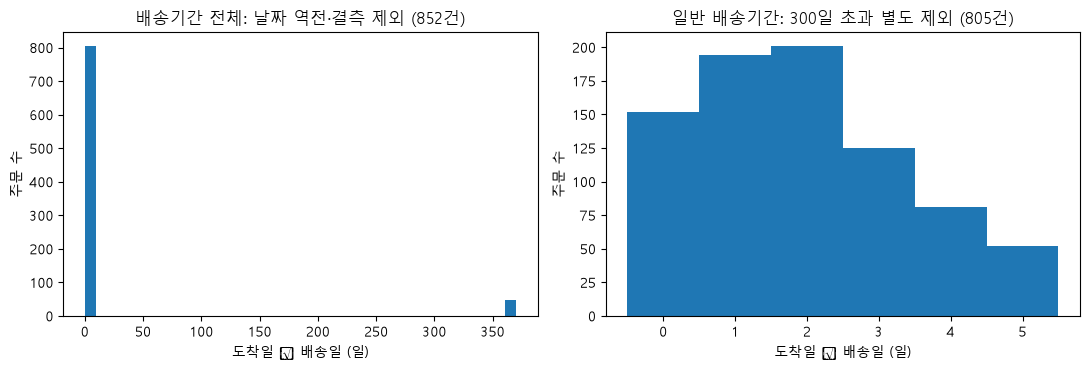

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
days.plot.hist(bins=40, ax=ax[0], title='배송기간 전체: 날짜 역전·결측 제외 (852건)')
regular_days.plot.hist(bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], ax=ax[1], title='일반 배송기간: 300일 초과 별도 제외 (805건)')
for axis in ax:
    axis.set_xlabel('도착일 − 배송일 (일)')
    axis.set_ylabel('주문 수')
plt.tight_layout()
plt.show()

**답 1:** 날짜 역전 147건과 날짜 결측 5건을 뺀 852건은 평균 **22.05일**, 중앙값 **2일**이며, 오른쪽의 **364~370일 47건**이 평균을 크게 끌어올립니다.  
**답 2:** 5일 다음 364일까지 관측 공백이 있고 날짜가 약 1년 차이 나는 덩어리여서 일반 배송기간 요약에서만 300일 초과를 제외했습니다. 남은 **805건의 평균 1.93일·중앙값 2일**을 보통 기간으로 제시하며, 오기라고 확정해 날짜를 고치거나 원본·정리 CSV의 행을 삭제하지 않았습니다.

## 단계 ⑥ / Q2 — 만족도가 낮을수록 반품이 많은가?
반품 여부를 True/False로 만들고 만족도별 평균을 비율로 계산합니다. 만족도 결측 30건은 이 질문에서만 제외하고 df와 정리 CSV에는 유지합니다. 각 만족도 그룹의 분모와 반품 건수도 같이 확인합니다.

만족도 관측: 974  결측 제외: 30


,주문 수,반품 수,반품 비율(%)
satisfaction,,,
1,224,17,7.59
2,184,22,11.96
3,192,15,7.81
4,172,15,8.72
5,202,14,6.93


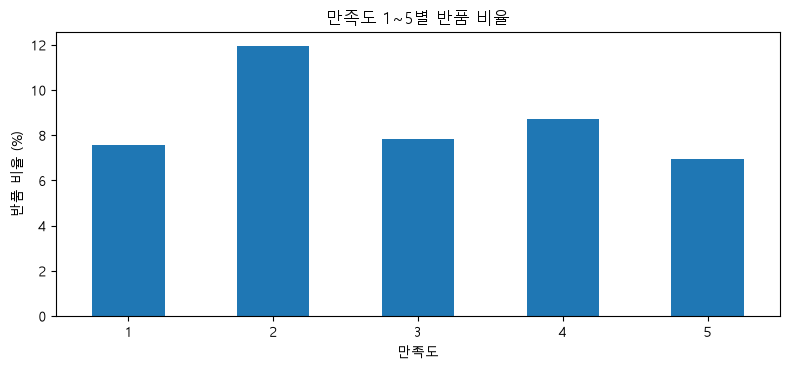

In [8]:
returned = df['status'] == '반품'
return_rate = returned.groupby(df['satisfaction']).mean().reindex([1, 2, 3, 4, 5]) * 100
return_counts = returned.groupby(df['satisfaction']).agg(['count', 'sum']).reindex([1, 2, 3, 4, 5])
return_table = return_counts.rename(columns={'count': '주문 수', 'sum': '반품 수'})
return_table['반품 비율(%)'] = return_rate
print('만족도 관측:', df['satisfaction'].count(), ' 결측 제외:', df['satisfaction'].isna().sum())
display(return_table.round(2))
return_rate.plot.bar(figsize=(8, 3.8), rot=0, title='만족도 1~5별 반품 비율')
plt.xlabel('만족도')
plt.ylabel('반품 비율 (%)')
plt.tight_layout()
plt.show()
assert int(return_counts['count'].sum()) == 974
assert return_rate.round(2).tolist() == [7.59, 11.96, 7.81, 8.72, 6.93]

**답 1:** 이 데이터에서는 **아니다**. 만족도 1→5의 반품 비율은 **7.59%, 11.96%, 7.81%, 8.72%, 6.93%**로, 만족도가 낮아질수록 일관되게 증가하지 않습니다.  
**답 2:** 가장 높은 비율은 만족도 **2의 22/184건(11.96%)**이고 만족도 **1은 17/224건(7.59%)**입니다. 만족도 결측 30건을 제외한 **974건**의 관찰이며, 인과관계나 통계적 유의성까지 주장하지 않습니다.

## 단계 ⑦ / Q3 — 카테고리 매출 1위의 이유는 무엇인가?
건수·매출 합·평균 단가·평균 수량을 groupby().agg()로 나란히 비교합니다. 날짜와 만족도를 사용하지 않는 질문이므로 Q1·Q2에서 제외한 행도 여기서는 유지합니다.

In [9]:
category_summary = df.groupby('category').agg(
    주문_건수=('total_sales', 'size'),
    매출_합계=('total_sales', 'sum'),
    평균_단가=('unit_price', 'mean'),
    평균_수량=('quantity', 'mean'),
).sort_values('매출_합계', ascending=False)
category_table = category_summary.rename(columns={'주문_건수': '건수', '매출_합계': '매출 합(원)', '평균_단가': '평균 단가(원)', '평균_수량': '평균 수량'})
display(category_table.round(2))
print('전체 집계 건수:', category_summary['주문_건수'].sum())
print('매출 1위:', category_summary.index[0], '매출:', round(category_summary.iloc[0]['매출_합계'] / 1e8, 2), '억 원')
print('건수 1위:', category_summary['주문_건수'].idxmax())
print('평균 단가 1위:', category_summary['평균_단가'].idxmax())
print('평균 수량 1위:', category_summary['평균_수량'].idxmax())
assert int(category_summary['주문_건수'].sum()) == 1004
assert category_summary.index[0] == '가구'

,건수,매출 합(원),평균 단가(원),평균 수량
category,,,,
가구,213,2.843337e+09,257322.91,51.04
식품,210,2.513274e+09,255232.93,47.31
전자제품,207,2.471628e+09,249651.61,47.96
도서,204,2.453240e+09,238500.64,49.50
의류,170,2.181904e+09,249447.16,51.61


전체 집계 건수: 1004
매출 1위: 가구 매출: 28.43 억 원
건수 1위: 가구
평균 단가 1위: 가구
평균 수량 1위: 의류


**답 1:** 매출 1위는 **가구, 약 28.43억 원**으로, 주문 **213건**과 평균 단가 **257,322.91원**이 모두 카테고리 중 가장 높습니다.  
**답 2:** 가구의 평균 수량 **51.04개**는 의류 **51.61개**보다 낮습니다. 표에서는 수량 단독보다 건수·단가의 높은 값이 두드러지며, 집계 비교이지 인과관계나 개별 요인의 기여도를 분리한 결론은 아닙니다.

## 제출 전 최종 확인
새 커널에서 단계 ①부터 다시 실행한 뒤 CSV와 분석 결과를 점검합니다. Q1의 분석용 제외가 단계 ④의 정리 파일을 바꾸지 않았는지도 확인합니다.

In [10]:
saved = pd.read_csv('sales_clean.csv')
assert raw_shape == (1030, 14)
assert duplicate_count == 26 and len(df) == 1004
assert repair_count == 22 and saved['quantity'].max() == 99
assert ((saved['total_sales'] - saved['quantity'] * saved['unit_price']).abs() > 1).sum() == 0
assert saved.shape == (1004, 15) and int(saved['date_error'].sum()) == 147
assert saved.isna().sum().drop('date_error').equals(missing_before)
assert len(days) == 852 and len(long_days) == 47 and len(regular_days) == 805
assert round(days.mean(), 2) == 22.05 and round(regular_days.mean(), 2) == 1.93
assert int(return_counts['count'].sum()) == 974
assert int(category_summary['주문_건수'].sum()) == 1004
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == source_sha256
print('PASS: ①~⑦ 전체 실행, 전처리 수치 일치, Q1~Q3 결과 확인, 원본 보존')
print('제출 파일: hw5.ipynb / sales_data.csv / sales_clean.csv / README.md')

PASS: ①~⑦ 전체 실행, 전처리 수치 일치, Q1~Q3 결과 확인, 원본 보존
제출 파일: hw5.ipynb / sales_data.csv / sales_clean.csv / README.md
